# AIA Project: Indian Liver Patient Dataset (ILPD)

**Goal:** Clean the dataset, explore correlations, compare machine learning models, and evaluate predictions. This is for education only, not diagnosis.

## 1. Import libraries and load dataset

In Google Colab, upload `ILPD_dataset.csv` using the Files panel, then run the cells in order.

In [10]:

import pandas as pd

DATA_PATH = '/content/ILPD_dataset.csv'
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (583, 11)


,age,gender,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
DATA_PATH = 'ILPD_dataset.csv'  # Change only if your uploaded filename is different
df = pd.read_csv(DATA_PATH)
print('Original shape:', df.shape)
display(df.head())

Original shape: (583, 11)


,age,gender,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


## 2. Inspect data quality

In [12]:
print('Data types:\n', df.dtypes)
print('\nMissing values:\n', df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nTarget counts before cleaning:\n', df['is_patient'].value_counts(dropna=False))

Data types:
 age                   int64
gender               object
tot_bilirubin       float64
direct_bilirubin    float64
tot_proteins          int64
albumin               int64
ag_ratio              int64
sgpt                float64
sgot                float64
alkphos             float64
is_patient            int64
dtype: object

Missing values:
 age                 0
gender              0
tot_bilirubin       0
direct_bilirubin    0
tot_proteins        0
albumin             0
ag_ratio            0
sgpt                0
sgot                0
alkphos             4
is_patient          0
dtype: int64

Duplicate rows: 13

Target counts before cleaning:
 is_patient
1    416
2    167
Name: count, dtype: int64


In [13]:

import pandas as pd

DATA_PATH = '/content/ILPD_dataset.csv'
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (583, 11)


,age,gender,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


## 3. Clean duplicate rows and prepare target

For the commonly used ILPD version, target value 1 means liver patient and 2 means non-liver patient. This is a dataset label, not a medical conclusion.

In [14]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=['is_patient']).copy()
df['is_patient'] = df['is_patient'].map({1: 'Liver patient', 2: 'Non-liver patient'})
if df['is_patient'].isna().any():
    raise ValueError('Unexpected target label; inspect is_patient values.')
print('Shape after cleaning:', df.shape)
print('Missing values after duplicate removal (features are imputed later):\n', df.isna().sum())
print('Target distribution:\n', df['is_patient'].value_counts())

Shape after cleaning: (570, 11)
Missing values after duplicate removal (features are imputed later):
 age                 0
gender              0
tot_bilirubin       0
direct_bilirubin    0
tot_proteins        0
albumin             0
ag_ratio            0
sgpt                0
sgot                0
alkphos             4
is_patient          0
dtype: int64
Target distribution:
 is_patient
Liver patient        406
Non-liver patient    164
Name: count, dtype: int64


## 4. Exploratory data analysis: correlation and target balance

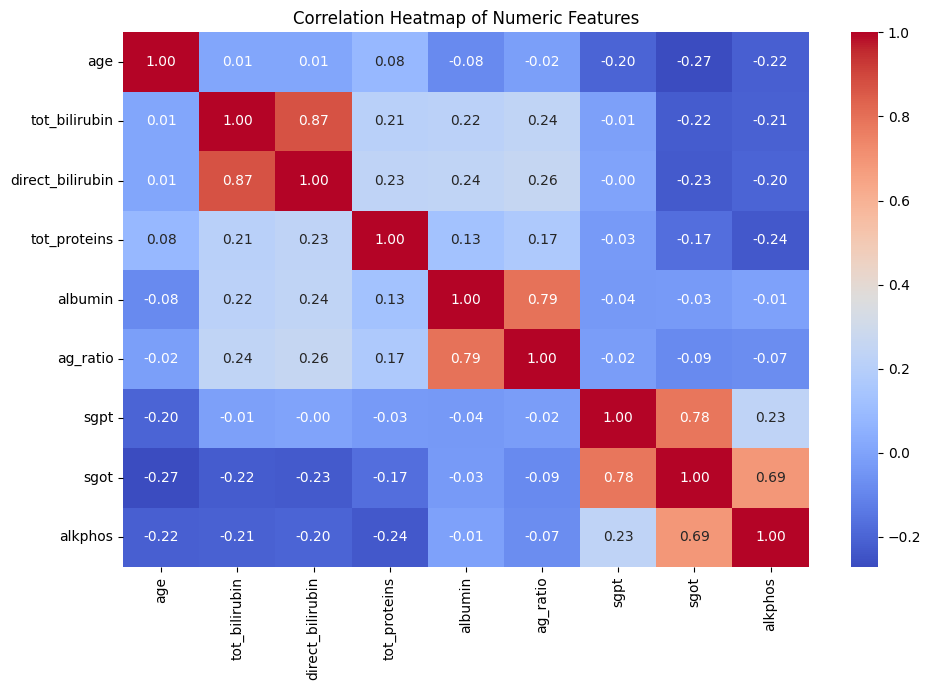

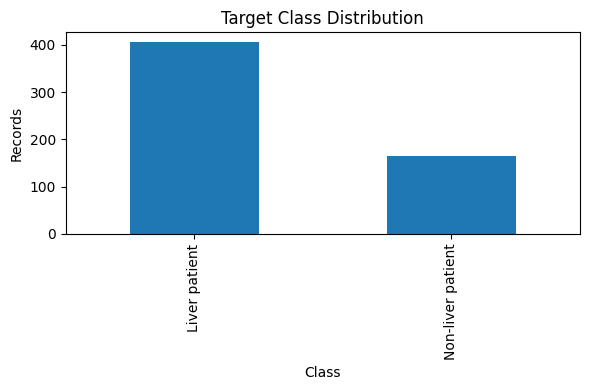

In [15]:
numeric_cols = df.select_dtypes(include='number').columns.tolist()
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
df['is_patient'].value_counts().plot(kind='bar')
plt.title('Target Class Distribution')
plt.xlabel('Class')
plt.ylabel('Records')
plt.tight_layout()
plt.show()

## 5. Split data and create preprocessing pipeline

The imputer, scaler, and encoder are inside a pipeline so they are fitted on the training data only.

In [16]:
X = df.drop(columns=['is_patient'])
y = df['is_patient']
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_features = X.select_dtypes(include='number').columns.tolist()

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_features), ('categorical', categorical_pipeline, categorical_features)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 456
Testing rows: 114


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")


Preprocessor created successfully!


## 6. Train and compare models

In [18]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced')
}
results = []
trained_models = {}
for name, estimator in models.items():
    model = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, pred),
                    'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
                    'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0),
                    'F1-score (macro)': f1_score(y_test, pred, average='macro', zero_division=0)})
results_df = pd.DataFrame(results).sort_values('F1-score (macro)', ascending=False)
display(results_df)
results_df.to_csv('model_comparison_results.csv', index=False)

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,0.657895,0.696023,0.732323,0.651868
1,Random Forest,0.666667,0.556068,0.540965,0.538953


## 7. Evaluate selected model

Selected model based on macro F1-score: Logistic Regression
                   precision    recall  f1-score   support

    Liver patient       0.94      0.56      0.70        81
Non-liver patient       0.45      0.91      0.61        33

         accuracy                           0.66       114
        macro avg       0.70      0.73      0.65       114
     weighted avg       0.80      0.66      0.67       114



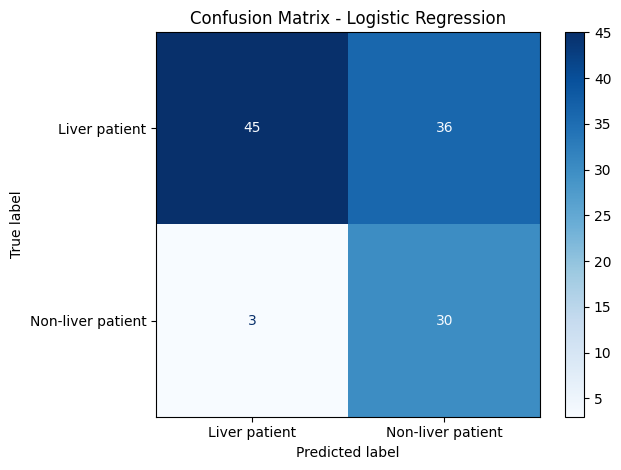

Saved best model: best_ilpd_model.joblib


In [19]:
best_name = results_df.iloc[0]['Model']
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)
print('Selected model based on macro F1-score:', best_name)
print(classification_report(y_test, y_pred, zero_division=0))
labels = ['Liver patient', 'Non-liver patient']
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix - {best_name}')
plt.tight_layout()
plt.show()
joblib.dump(best_model, 'best_ilpd_model.joblib')
print('Saved best model: best_ilpd_model.joblib')

## 8. Conclusion

Use the metric table and confusion matrix generated above to write your conclusion. Do not claim a model is clinically reliable based on this assignment. ILPD is a limited educational dataset and this model must not be used for diagnosis or treatment.